In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro
from scipy.stats import ranksums
from stats import (load_data, split_groups, cliffs_delta, cliffs_magnitude,
                   bootstrap_ci_median, bootstrap_ci_median_difference)

np.random.seed(4928)  # fixed seed: every bootstrap CI now re-runs exactly

In [2]:
task1_df, task2_df = load_data()
os.makedirs("figures", exist_ok=True)

In [3]:
task1_ai_group, task1_manual_group, task2_treatment, task2_control = split_groups(task1_df, task2_df)

In [4]:
# Define color scheme
colors = {
    'ai_dark_gray': '#4F4F4F',
    'manual_work': 'yellow',
    'treatment_blue': '#1f77b4',  # Blue for treatment
    'control_orange': '#ff7f0e'  # Orange for control
}

# Test runs

In [5]:
# Task 1 descriptive statistics for test runs by AI group
task1_tc_stats = (
    task1_df.groupby('ai')['test_runs']
    .describe()[['count', 'mean', 'std', 'min', '50%', 'max']]
    .rename(columns={'count': 'N', '50%': 'median'})
)

# Task 2 descriptive statistics for test runs by treatment group
task2_tc_stats = (
    task2_df.groupby('treatment')['test_runs']
    .describe()[['count', 'mean', 'std', 'min', '50%', 'max']]
    .rename(columns={'count': 'N', '50%': 'median'})
)

# Display results
print("Task 1 test runs Descriptive Statistics:")
print(task1_tc_stats)
print("\nTask 2 test runs Descriptive Statistics:")
print(task2_tc_stats)

Task 1 test runs Descriptive Statistics:
          N      mean        std  min  median    max
ai                                                  
False  32.0   5.90625   5.275380  1.0     4.0   18.0
True   37.0  15.27027  46.935327  1.0     5.0  287.0

Task 2 test runs Descriptive Statistics:
              N       mean        std  min  median   max
treatment                                               
ai         36.0  10.194444  11.732298  1.0     6.0  46.0
human      34.0   7.558824   7.295458  1.0     5.5  41.0


# Task 1

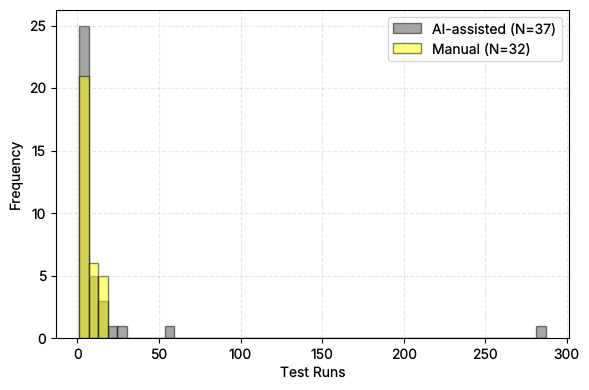

In [6]:
plt.figure(figsize=(6, 4))

# Drop NaNs and count
ai_test_runs = task1_ai_group['test_runs'].dropna()
manual_test_runs = task1_manual_group['test_runs'].dropna()

# Legend labels with sample sizes
ai_label = f"AI-assisted (N={len(ai_test_runs)})"
manual_label = f"Manual (N={len(manual_test_runs)})"

# Determine combined min/max for consistent binning
combined_min = min(ai_test_runs.min(), manual_test_runs.min())
combined_max = max(ai_test_runs.max(), manual_test_runs.max())
bins = np.linspace(combined_min, combined_max, 50)

# Plot histograms
plt.hist(ai_test_runs, bins=bins, 
         color=colors['ai_dark_gray'], alpha=0.5, edgecolor='black', label=ai_label)
plt.hist(manual_test_runs, bins=bins, 
         color=colors['manual_work'], alpha=0.5, edgecolor='black', label=manual_label)

# Labels and style
plt.xlabel('Test Runs')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()

plt.savefig("figures/task1_test_runs_distribution.png", dpi=300)
plt.show()

# Task 2

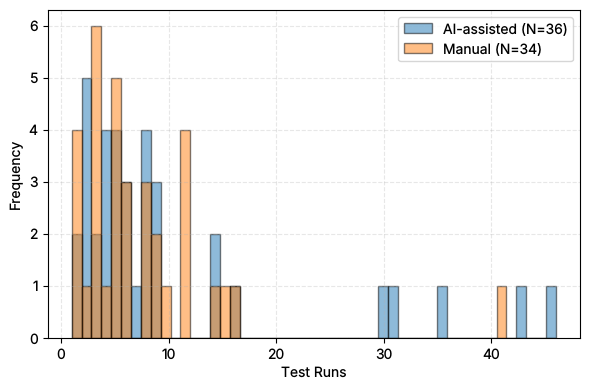

In [7]:
plt.figure(figsize=(6, 4))

# Drop NaNs and count
treatment_test_runs = task2_treatment['test_runs'].dropna()
control_test_runs = task2_control['test_runs'].dropna()

# Legend labels with sample sizes
treatment_label = f"AI-assisted (N={len(treatment_test_runs)})"
control_label = f"Manual (N={len(control_test_runs)})"

# Determine combined min/max for consistent binning
combined_min = min(treatment_test_runs.min(), control_test_runs.min())
combined_max = max(treatment_test_runs.max(), control_test_runs.max())
bins = np.linspace(combined_min, combined_max, 50)

# Plot histograms
plt.hist(treatment_test_runs, bins=bins, 
         color=colors['treatment_blue'], alpha=0.5, edgecolor='black', label=treatment_label)
plt.hist(control_test_runs, bins=bins, 
         color=colors['control_orange'], alpha=0.5, edgecolor='black', label=control_label)

# Labels and style
plt.xlabel('Test Runs')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()

plt.savefig("figures/task2_test_runs_distribution.png", dpi=300)
plt.show()

## Inferential statistics

In [8]:
treatment = task2_treatment['test_runs'].dropna()
control = task2_control['test_runs'].dropna()

# Step 1: Perform the Shapiro-Wilk test for normality
shapiro_treatment = shapiro(treatment)
shapiro_control = shapiro(control)

# Step 2: Display the results
print("Shapiro-Wilk Test for Normality:")
print(f"Treatment Group: W={shapiro_treatment.statistic:.4f}, p-value={shapiro_treatment.pvalue:.4e}")
print(f"Control Group: W={shapiro_control.statistic:.4f}, p-value={shapiro_control.pvalue:.4e}")

Shapiro-Wilk Test for Normality:
Treatment Group: W=0.6926, p-value=2.1715e-07
Control Group: W=0.7044, p-value=5.7452e-07


We reject the null hypothesis of normality.

In [9]:
# Step 2: Wilcoxon Rank-Sum Test (non-parametric test)
statistic, p_value = ranksums(treatment, control)
print(f"Wilcoxon Rank-Sum Test: Statistic={statistic:.4f}, p-value={p_value:.4e}")

Wilcoxon Rank-Sum Test: Statistic=0.3349, p-value=7.3770e-01


We do not reject the null hypothesis of no difference.

In [10]:
# Compute Cliff's delta for Test Runs
delta_test_runs = cliffs_delta(task2_treatment['test_runs'], task2_control['test_runs'])

# Print result
print(f"Cliff's Delta for Test Runs: {delta_test_runs:.4f}")

# Interpret effect size magnitude
abs_delta = abs(delta_test_runs)
magnitude = cliffs_magnitude(abs_delta).capitalize()

print(f"Effect Size Interpretation: {magnitude}")

Cliff's Delta for Test Runs: 0.0466
Effect Size Interpretation: Negligible


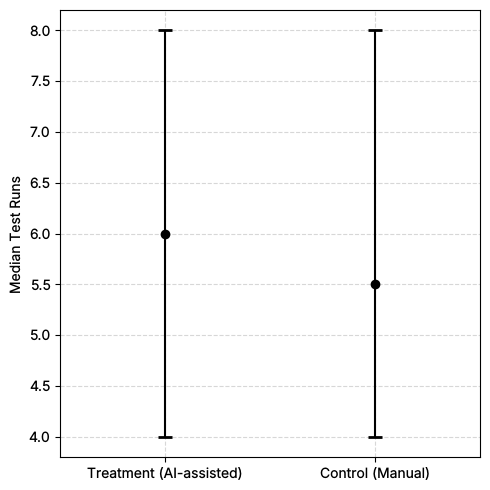

Bootstrap Confidence Intervals (95% CI) for Median Test Runs:
Treatment (AI-assisted): 6.00  (95% CI: 4.00 - 8.00)
Control (Manual):       5.50  (95% CI: 4.00 - 8.00)


In [11]:
# Compute Bootstrap CIs for median Test Runs in Task 2
treatment_median, treatment_lower, treatment_upper = bootstrap_ci_median(task2_treatment['test_runs'].dropna())
control_median, control_lower, control_upper = bootstrap_ci_median(task2_control['test_runs'].dropna())

# Error bars
lower_bounds = [treatment_median - treatment_lower, control_median - control_lower]
upper_bounds = [treatment_upper - treatment_median, control_upper - control_median]
yerr = [lower_bounds, upper_bounds]

# Plot
plt.figure(figsize=(5, 5))
x_pos = [0, 1]
medians = [treatment_median, control_median]

plt.errorbar(x_pos, medians, yerr=yerr, fmt='o', capsize=5, capthick=2, color='black')
plt.xticks(x_pos, ['Treatment (AI-assisted)', 'Control (Manual)'])
plt.xlim(-0.5, 1.5)
plt.ylabel('Median Test Runs')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("figures/task2_bootstrap_test_runs_ci.png", dpi=300)
plt.show()

# Print summary
print("Bootstrap Confidence Intervals (95% CI) for Median Test Runs:")
print(f"Treatment (AI-assisted): {treatment_median:.2f}  (95% CI: {treatment_lower:.2f} - {treatment_upper:.2f})")
print(f"Control (Manual):       {control_median:.2f}  (95% CI: {control_lower:.2f} - {control_upper:.2f})")

In [12]:
# Extract test_runs values
test_runs_treatment = task2_treatment["test_runs"].dropna().to_numpy()
test_runs_control   = task2_control["test_runs"].dropna().to_numpy()

# Compute bootstrap CI for the median difference
tr_diff, tr_lower, tr_upper = bootstrap_ci_median_difference(
    test_runs_treatment, test_runs_control
)

print("Bootstrap CI for the median Test Runs difference (Treatment - Control):")
print(f"Median difference: {tr_diff:.3f}")
print(f"95% CI: [{tr_lower:.3f}, {tr_upper:.3f}]")

Bootstrap CI for the median Test Runs difference (Treatment - Control):
Median difference: 0.500
95% CI: [-3.000, 3.000]
